# Evaluation & Final Integration — ARTI 502
Evaluates both models on the **same held-out test set** and produces: metrics table, confusion matrices, ROC curves, per-class comparison.

**Expected input from each model owner (in `results/`):**
- `model1_preds.csv` / `model2_preds.csv` with columns `y_true, y_pred`
- `model1_probs.npy` / `model2_probs.npy` → array of shape `(N, num_classes)` (softmax output)

Set `USE_DUMMY = True` to test the notebook now before the real models are ready.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report, roc_curve, auc, roc_auc_score)
from sklearn.preprocessing import label_binarize

USE_DUMMY   = False
NUM_CLASSES = 43
MODEL_NAMES = ["Custom CNN", "YOLOv8n-cls"]
FILES       = ["model1", "model2"]
BASE    = "/content/drive/MyDrive/ARTI502_Project"
RES_DIR = f"{BASE}/results"; FIG_DIR = f"{BASE}/figures"
os.makedirs(RES_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

Mounted at /content/drive


## 1. Load predictions

In [2]:
def make_dummy(n=2000, acc=0.9, seed=0):
    rng = np.random.default_rng(seed)
    y_true = rng.integers(0, NUM_CLASSES, n)
    logits = rng.normal(size=(n, NUM_CLASSES))
    correct = rng.random(n) < acc
    logits[np.arange(n), y_true] += np.where(correct, 5, 0)
    probs = np.exp(logits) / np.exp(logits).sum(1, keepdims=True)
    return y_true, probs.argmax(1), probs

data = {}
for i, (name, f) in enumerate(zip(MODEL_NAMES, FILES)):
    if USE_DUMMY:
        y_true, y_pred, probs = make_dummy(acc=0.85 + 0.08*i, seed=i)
    else:
        df = pd.read_csv(f"{RES_DIR}/{f}_preds.csv")
        y_true, y_pred = df.y_true.values, df.y_pred.values
        probs = np.load(f"{RES_DIR}/{f}_probs.npy")
    data[name] = dict(y_true=y_true, y_pred=y_pred, probs=probs)
    print(f"{name}: {len(y_true)} test samples")

# sanity check: both models must be evaluated on the SAME test set
if not USE_DUMMY:
    a, b = [d["y_true"] for d in data.values()]
    assert len(a) == len(b) and (a == b).all(), "Test sets differ! Ask members 2/3/4 to use the same split."


Custom CNN: 12630 test samples
YOLOv8n-cls: 12630 test samples


## 2. Metrics table

In [3]:
rows = []
for name, d in data.items():
    yt, yp, pr = d["y_true"], d["y_pred"], d["probs"]
    p_m, r_m, f_m, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(yt, yp, average="weighted", zero_division=0)
    if NUM_CLASSES == 2:
        roc_auc = roc_auc_score(yt, pr[:, 1])
    else:
        roc_auc = roc_auc_score(yt, pr, multi_class="ovr", average="macro", labels=range(NUM_CLASSES))
    rows.append({"Model": name, "Accuracy": accuracy_score(yt, yp),
                 "Precision (macro)": p_m, "Recall (macro)": r_m, "F1 (macro)": f_m,
                 "F1 (weighted)": f_w, "ROC-AUC": roc_auc})

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv(f"{RES_DIR}/comparison_table.csv")
display(results)
print(results.to_markdown())   # paste into the report

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC
Model,,,,,,
Custom CNN,0.9360,0.9102,0.9083,0.9033,0.936,0.997
YOLOv8n-cls,0.9891,0.9882,0.9830,0.9844,0.989,1.000


| Model       |   Accuracy |   Precision (macro) |   Recall (macro) |   F1 (macro) |   F1 (weighted) |   ROC-AUC |
|:------------|-----------:|--------------------:|-----------------:|-------------:|----------------:|----------:|
| Custom CNN  |     0.936  |              0.9102 |           0.9083 |       0.9033 |           0.936 |     0.997 |
| YOLOv8n-cls |     0.9891 |              0.9882 |           0.983  |       0.9844 |           0.989 |     1     |


## 3. Confusion matrices

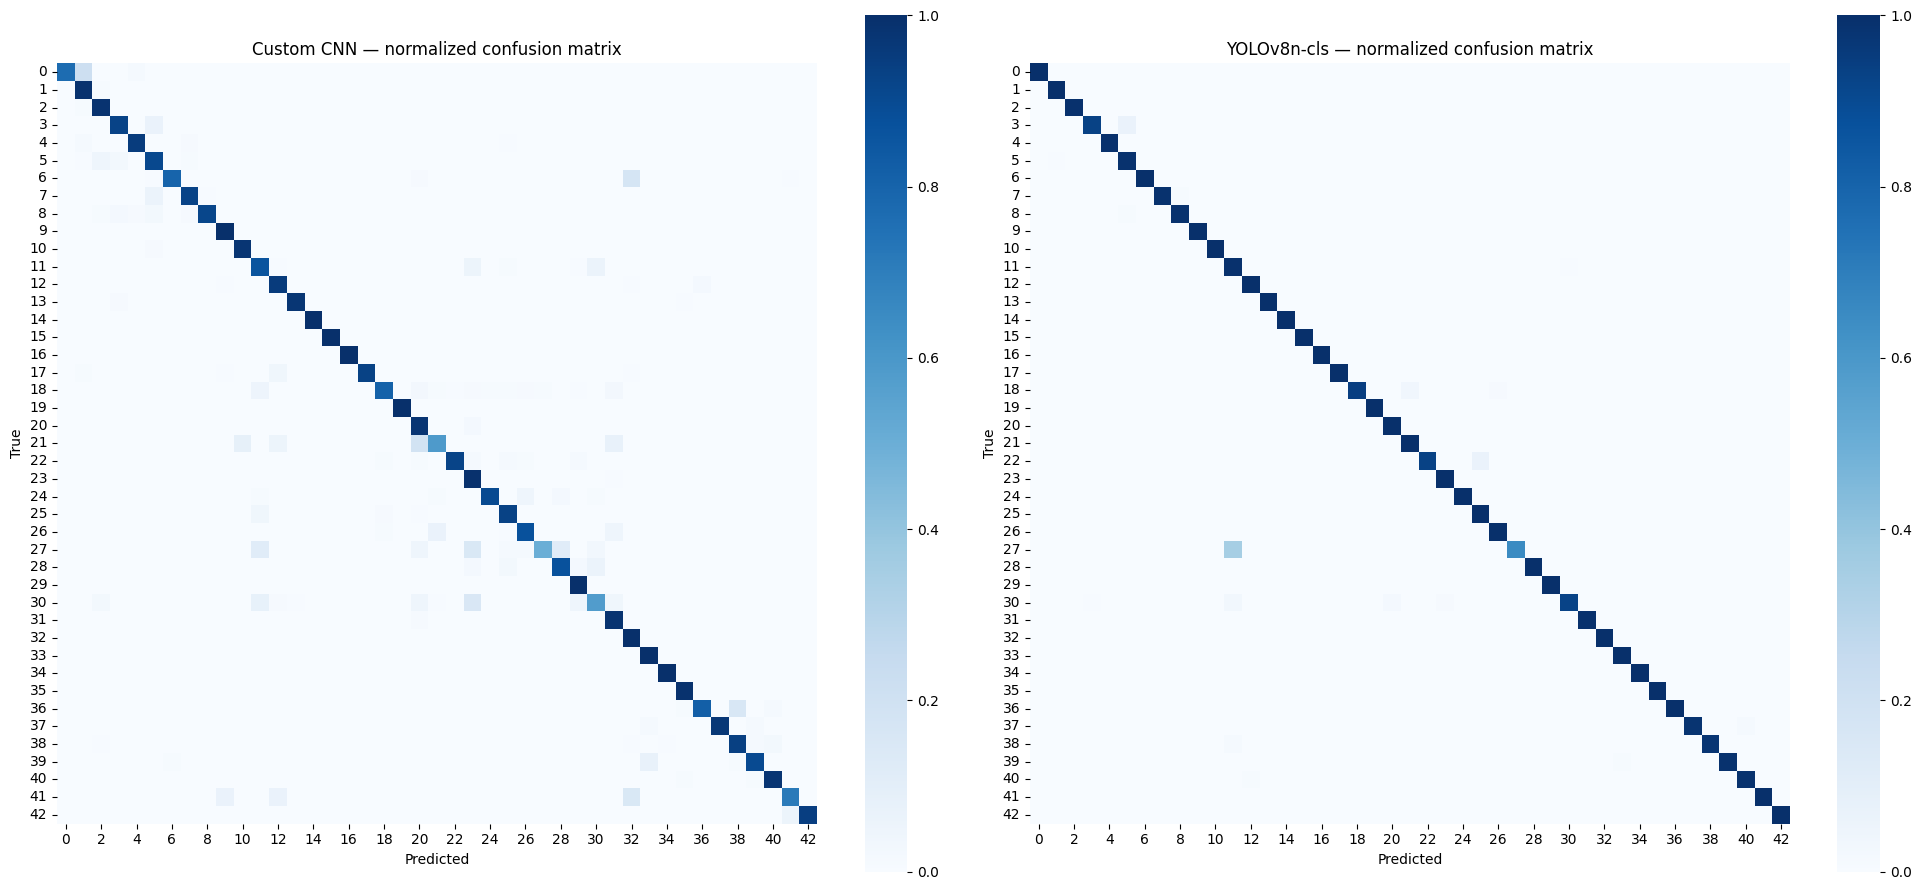

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, (name, d) in zip(axes, data.items()):
    cm = confusion_matrix(d["y_true"], d["y_pred"], labels=range(NUM_CLASSES), normalize="true")
    sns.heatmap(cm, ax=ax, cmap="Blues", vmin=0, vmax=1, square=True,
                annot=NUM_CLASSES <= 10, fmt=".2f", cbar=True)
    ax.set_title(f"{name} — normalized confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=200); plt.show()

## 4. ROC curves

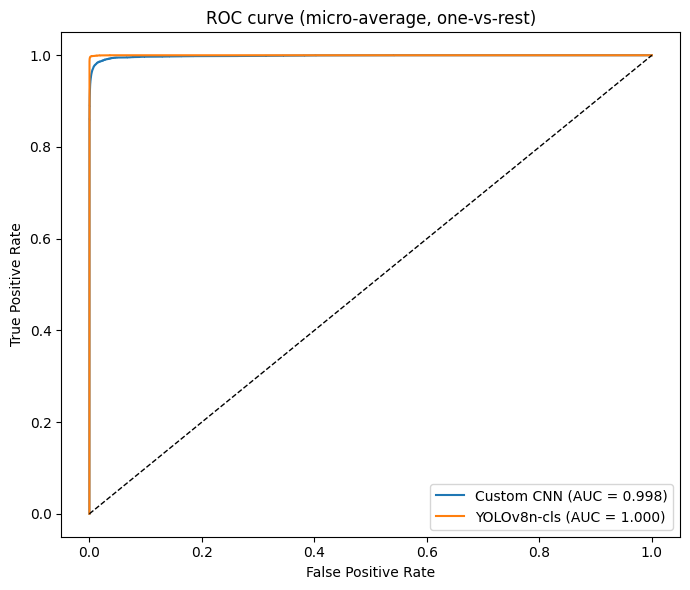

In [5]:
plt.figure(figsize=(7, 6))
for name, d in data.items():
    yt, pr = d["y_true"], d["probs"]
    if NUM_CLASSES == 2:
        fpr, tpr, _ = roc_curve(yt, pr[:, 1])
    else:   # micro-average one-vs-rest
        yb = label_binarize(yt, classes=range(NUM_CLASSES))
        fpr, tpr, _ = roc_curve(yb.ravel(), pr.ravel())
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve" + ("" if NUM_CLASSES == 2 else " (micro-average, one-vs-rest)"))
plt.legend(); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/roc_curves.png", dpi=200); plt.show()

## 5. Per-class comparison (where does each model fail?)

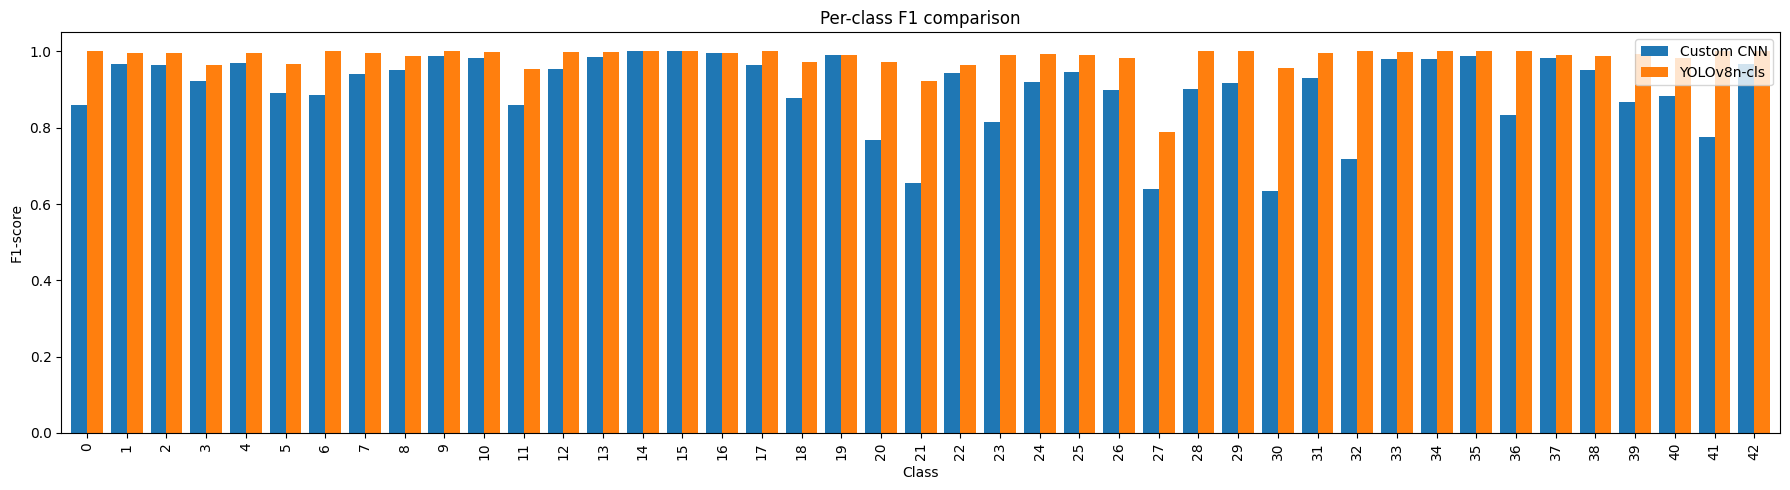

5 weakest classes per model:
Custom CNN → {30: 0.635, 27: 0.638, 21: 0.654, 32: 0.719, 20: 0.769}
YOLOv8n-cls → {27: 0.788, 21: 0.923, 11: 0.954, 30: 0.955, 3: 0.963}


In [6]:
per_class = {}
for name, d in data.items():
    _, _, f, _ = precision_recall_fscore_support(d["y_true"], d["y_pred"], labels=range(NUM_CLASSES), zero_division=0)
    per_class[name] = f
pc = pd.DataFrame(per_class); pc.index.name = "Class"
pc.to_csv(f"{RES_DIR}/per_class_f1.csv")

pc.plot(kind="bar", figsize=(18, 5), width=0.8)
plt.ylabel("F1-score"); plt.title("Per-class F1 comparison"); plt.ylim(0, 1.05)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/per_class_f1.png", dpi=200); plt.show()

print("5 weakest classes per model:")
for name in pc: print(name, "→", pc[name].nsmallest(5).round(3).to_dict())

## 6. Overall comparison bar chart (for report & slides)

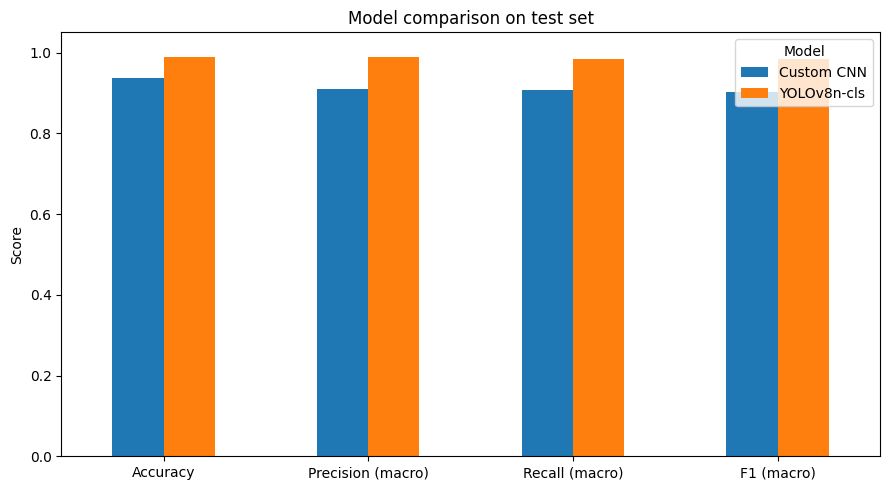

In [7]:
results[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].T.plot(kind="bar", figsize=(9, 5))
plt.ylim(0, 1.05); plt.ylabel("Score"); plt.title("Model comparison on test set"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/model_comparison.png", dpi=200); plt.show()

## 7. Optional extras (fill in from members 3 & 4)
Efficiency matters for the discussion (e.g. MobileNetV2 is designed to be light).

In [8]:
efficiency = pd.DataFrame({
    "Model": MODEL_NAMES,
    "Parameters (M)":       [None, None],   # sum(p.numel() for p in model.parameters())/1e6
    "Training time (min)":  [None, None],
    "Inference ms / image": [None, None],
}).set_index("Model")
display(efficiency)

,Parameters (M),Training time (min),Inference ms / image
Model,,,
Custom CNN,None,None,None
YOLOv8n-cls,None,None,None


---
## Snippet to send to members 3 & 4 (how to save predictions)
**PyTorch**
```python
model.eval(); ys, ps = [], []
with torch.no_grad():
    for x, y in test_loader:
        ps.append(torch.softmax(model(x.to(device)), 1).cpu()); ys.append(y)
probs = torch.cat(ps).numpy(); y_true = torch.cat(ys).numpy()
pd.DataFrame({"y_true": y_true, "y_pred": probs.argmax(1)}).to_csv("results/model1_preds.csv", index=False)
np.save("results/model1_probs.npy", probs)
torch.save(model.state_dict(), "models/model1.pt")
```
**Keras**
```python
probs = model.predict(test_ds)                       # test_ds must NOT be shuffled
y_true = np.concatenate([y for _, y in test_ds])
pd.DataFrame({"y_true": y_true, "y_pred": probs.argmax(1)}).to_csv("results/model1_preds.csv", index=False)
np.save("results/model1_probs.npy", probs)
model.save("models/model1.keras")
```